# 03 · Khine: clustering passengers (K-means) + report charts

**Question:** are there natural groups of passengers, and how satisfied is each group?

1. Pick the columns that describe a passenger and their trip, and scale them
2. K-means for k = 2 … 8: inertia (elbow) and silhouette score (on a 20,000-row sample, as the README says)
3. Choose k, describe each cluster, and compare satisfaction rates
4. Charts for the report
5. Updated chart: our Kaggle scores (v1, v3) vs the final leaderboard

`satisfaction` is **not** used to build the clusters. We only look at it afterwards, to see whether the
groups K-means finds without it differ in satisfaction.

Runtime: about 5 minutes.

In [1]:
import sys, time
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

from src.clean import load_data, RATINGS, TARGET

train, _ = load_data()
print(train.shape)

(699635, 23)


## 1. Columns for clustering
* 13 service ratings. 0 means "not applicable", so a 0 is replaced by that column's median (a neutral value)
  instead of being read as "terrible".
* Age, flight distance and total delay (log, because they are skewed)
* Class (Business = 1, Eco Plus = 0.5, Eco = 0), business travel (1/0), loyal customer (1/0)

Everything is scaled to mean 0 and standard deviation 1, so no column dominates just because its numbers are bigger.

In [2]:
C = pd.DataFrame(index=train.index)
for r in RATINGS:
    col = train[r].replace(0, np.nan)
    C[r] = col.fillna(col.median())
C['Age'] = train['Age']
C['log Flight Distance'] = np.log1p(train['Flight Distance'])
delay = train['Departure Delay in Minutes'] + train['Arrival Delay in Minutes'].fillna(train['Departure Delay in Minutes'])
C['log total delay'] = np.log1p(delay)
C['Class level'] = train['Class'].map({'Business': 1.0, 'Eco Plus': 0.5, 'Eco': 0.0})
C['Business travel'] = (train['Type of Travel'] == 'Business travel').astype(float)
C['Loyal customer'] = (train['Customer Type'] == 'Loyal Customer').astype(float)

assert C.notna().all().all()
Z = StandardScaler().fit_transform(C)
print('clustering columns:', C.shape[1])

clustering columns: 19


## 2. How many clusters?
* **Inertia** always goes down as k goes up; we look for the "elbow" where it stops dropping quickly.
* **Silhouette** (−1 to 1) measures how well each passenger fits its own cluster compared with the nearest
  other one. Higher is better. It is slow on 700k rows, so it is computed on a 20,000-row sample.

k=2: silhouette 0.1635 · 14s


k=3: silhouette 0.1325 · 16s


k=4: silhouette 0.1438 · 15s


k=5: silhouette 0.1512 · 20s


k=6: silhouette 0.1560 · 13s


k=7: silhouette 0.1600 · 23s


k=8: silhouette 0.1583 · 18s


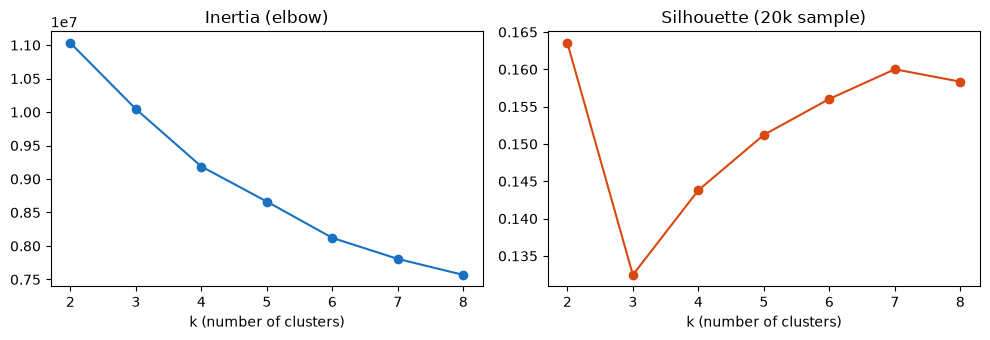

,inertia,silhouette
k,,
2,1.103208e+07,0.1635
3,1.004429e+07,0.1325
4,9.186742e+06,0.1438
5,8.662997e+06,0.1512
6,8.120801e+06,0.1560
7,7.806823e+06,0.1600
8,7.568145e+06,0.1583


In [3]:
rng = np.random.default_rng(0)
sample = rng.choice(len(Z), 20_000, replace=False)
rows = []
for k in range(2, 9):
    t = time.time()
    km = KMeans(n_clusters=k, n_init=4, random_state=0).fit(Z)
    sil = silhouette_score(Z[sample], km.labels_[sample])
    rows.append({'k': k, 'inertia': km.inertia_, 'silhouette': sil})
    print(f'k={k}: silhouette {sil:.4f} · {time.time()-t:.0f}s')
scores = pd.DataFrame(rows).set_index('k')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
scores['inertia'].plot(ax=axes[0], marker='o', color='#1971c2'); axes[0].set_title('Inertia (elbow)')
scores['silhouette'].plot(ax=axes[1], marker='o', color='#d9480f'); axes[1].set_title('Silhouette (20k sample)')
for ax in axes: ax.set_xlabel('k (number of clusters)')
plt.tight_layout(); plt.savefig('../report/figures/kmeans_choose_k.png', dpi=150); plt.show()
scores.round(4)

## 3. Final clusters
We take the k with the best silhouette score, but at least 3, because 2 groups say little about passengers.

In [4]:
best_k = int(scores.loc[3:, 'silhouette'].idxmax())
km = KMeans(n_clusters=best_k, n_init=10, random_state=0).fit(Z)
train['cluster'] = km.labels_
sil = silhouette_score(Z[sample], km.labels_[sample])
print(f'k = {best_k}, silhouette = {sil:.4f}')

# order clusters from least to most satisfied, so cluster numbers are easy to talk about
order = train.groupby('cluster')[TARGET].mean().sort_values().index
train['cluster'] = train['cluster'].map({old: new for new, old in enumerate(order)})

profile = C.assign(cluster=train['cluster']).groupby('cluster').mean()
summary = pd.DataFrame({
    'passengers': train['cluster'].value_counts().sort_index(),
    'share %': (train['cluster'].value_counts(normalize=True).sort_index() * 100).round(1),
    'satisfied %': (train.groupby('cluster')[TARGET].mean() * 100).round(1),
    'Business class %': (train.assign(b=train['Class'] == 'Business').groupby('cluster')['b'].mean() * 100).round(1),
    'business travel %': (profile['Business travel'] * 100).round(1),
    'loyal %': (profile['Loyal customer'] * 100).round(1),
    'mean age': profile['Age'].round(1),
    'mean rating': profile[RATINGS].mean(axis=1).round(2),
})
summary

k = 7, silhouette = 0.1600


,passengers,share %,satisfied %,Business class %,business travel %,loyal %,mean age,mean rating
cluster,,,,,,,,
0,91653,13.1,10.6,8.9,24.5,100.0,33.0,2.65
1,111168,15.9,11.3,1.4,3.0,100.0,38.1,3.53
2,56972,8.1,12.4,27.1,99.9,0.6,28.2,3.29
3,59605,8.5,21.8,38.9,99.9,0.0,28.5,2.77
4,108596,15.5,21.8,43.2,78.4,99.7,44.6,2.79
5,132266,18.9,88.7,86.8,98.8,95.6,43.1,4.19
6,139375,19.9,91.1,94.8,99.9,99.9,44.3,3.51


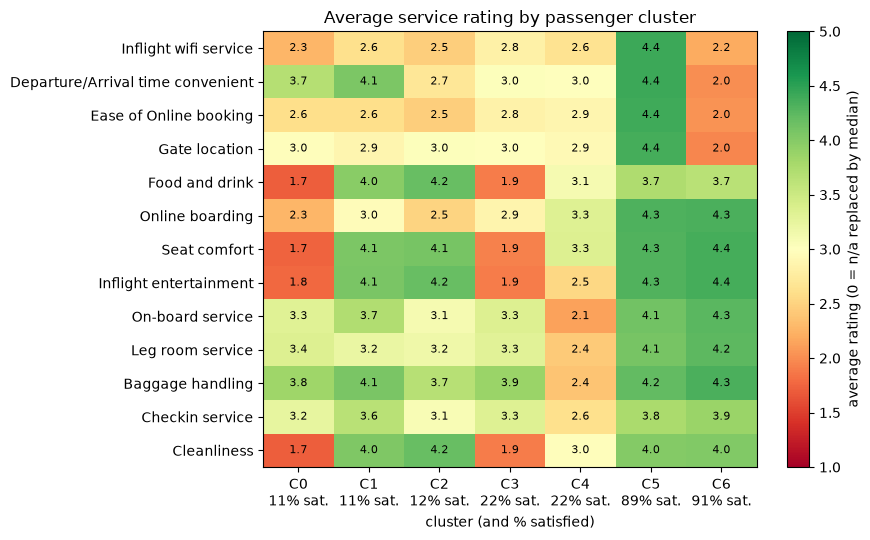

In [5]:
# Average rating per cluster: which services each group rates high or low
fig, ax = plt.subplots(figsize=(9, 5.5))
heat = profile[RATINGS].T
im = ax.imshow(heat, cmap='RdYlGn', vmin=1, vmax=5, aspect='auto')
ax.set_yticks(range(len(RATINGS)), RATINGS)
ax.set_xticks(range(best_k), [f'C{c}\n{summary.loc[c, "satisfied %"]:.0f}% sat.' for c in heat.columns])
ax.set_xlabel('cluster (and % satisfied)')
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f'{heat.iat[i, j]:.1f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, label='average rating (0 = n/a replaced by median)')
ax.set_title('Average service rating by passenger cluster')
plt.tight_layout(); plt.savefig('../report/figures/kmeans_cluster_ratings.png', dpi=150); plt.show()

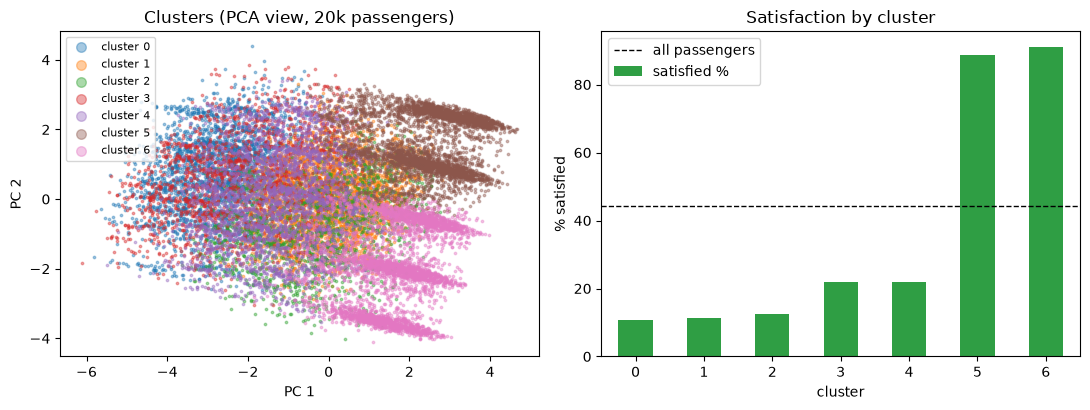

In [6]:
# 2-D picture of the clusters (PCA) on the 20k sample
pts = PCA(n_components=2, random_state=0).fit_transform(Z[sample])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for c in range(best_k):
    m = train['cluster'].to_numpy()[sample] == c
    axes[0].scatter(pts[m, 0], pts[m, 1], s=3, alpha=0.4, label=f'cluster {c}')
axes[0].set_title('Clusters (PCA view, 20k passengers)'); axes[0].legend(markerscale=4, fontsize=8)
axes[0].set_xlabel('PC 1'); axes[0].set_ylabel('PC 2')

summary['satisfied %'].plot.bar(ax=axes[1], color='#2f9e44')
axes[1].axhline(train[TARGET].mean() * 100, color='black', ls='--', lw=1, label='all passengers')
axes[1].set_ylabel('% satisfied'); axes[1].set_title('Satisfaction by cluster'); axes[1].legend()
axes[1].set_xlabel('cluster'); axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.savefig('../report/figures/kmeans_clusters_satisfaction.png', dpi=150); plt.show()

## 4. Chart for the report: our Kaggle scores vs the final leaderboard
Private scores from our late submissions (see the README results log), against the final private leaderboard.

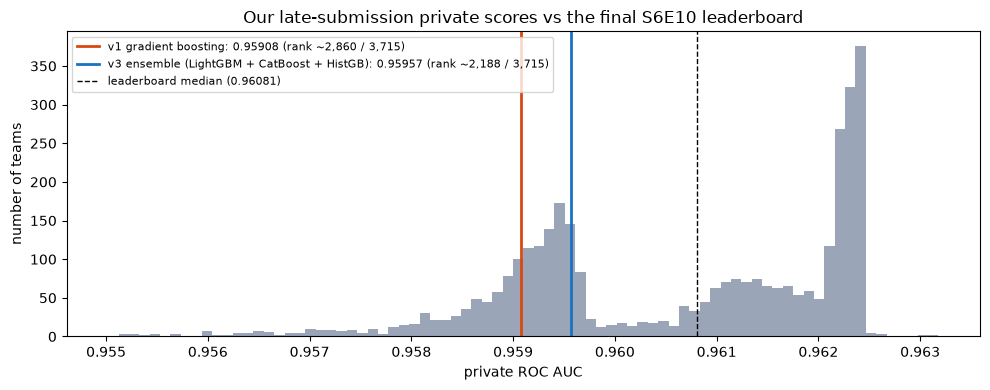

In [7]:
lb = pd.read_csv('../report/leaderboard_private_2026-11-26.csv')
lb = lb[lb['Score'] > 0.5]
ours = {'v1 gradient boosting': 0.95908, 'v3 ensemble (LightGBM + CatBoost + HistGB)': 0.95957}

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(lb['Score'][lb['Score'] > 0.955], bins=80, color='#9aa5b8')
for (name, s), c in zip(ours.items(), ['#d9480f', '#1971c2']):
    r = int((lb['Score'] > s).sum()) + 1
    ax.axvline(s, color=c, lw=2, label=f'{name}: {s:.5f} (rank ~{r:,} / {len(lb):,})')
ax.axvline(lb['Score'].median(), color='black', ls='--', lw=1, label=f"leaderboard median ({lb['Score'].median():.5f})")
ax.set_xlabel('private ROC AUC'); ax.set_ylabel('number of teams')
ax.set_title('Our late-submission private scores vs the final S6E10 leaderboard')
ax.legend(fontsize=8, loc='upper left')
plt.tight_layout(); plt.savefig('../report/figures/kaggle_scores_vs_leaderboard.png', dpi=150); plt.show()

## What the clusters tell us (run 2026-11-27)
**k = 7, silhouette 0.160.** The silhouette is low (k = 2 was slightly higher at 0.164, but 2 groups say
little), so the groups overlap. They are a useful *description* of passenger types, not sharp segments.

**Satisfaction splits the passengers into two worlds**, even though `satisfaction` was not used to build the clusters:

| Cluster | Share | Satisfied | Who they are | Ratings |
|---|---|---|---|---|
| C6 | 19.9% | 91% | Loyal business travellers, 95% Business class, age ~44 | High on board (seat, entertainment, online boarding ~4.3); **low** on wifi, booking, time, gate (~2) |
| C5 | 18.9% | 89% | Business travellers, 87% Business class, age ~43 | High on everything (~4.2–4.4) |
| C4 | 15.5% | 22% | Loyal, older (~45), mostly business travel, 43% Business class | Low on on-board service, leg room, baggage (2.1–2.4) |
| C3 | 8.5% | 22% | **Disloyal**, young (~28) business travellers | Very low seat, food, entertainment, cleanliness (~1.9) |
| C2 | 8.1% | 12% | **Disloyal**, young (~28) business travellers | Good on board (~4.1), weak digital (~2.5) |
| C1 | 15.9% | 11% | Loyal **personal** travellers, almost all Economy | Good on board (~4.0), still unsatisfied |
| C0 | 13.1% | 11% | Loyal, younger (~33), mostly personal travel | Very low seat, food, entertainment, cleanliness (~1.7) |

* The two satisfied clusters (C5, C6, about 39% of passengers) are business travellers in Business class
  with a good **on-board** experience. C6 shows that poor wifi, booking or gate ratings do not stop them being satisfied.
* Personal travellers in Economy (C1) are rarely satisfied even when they rate the on-board service well.
* Disloyal customers (C2, C3) are dissatisfied whatever their ratings.
* This matches the models: Type of Travel, Class, Customer Type and Online boarding are among the strongest features.